# 🍊 Orange Vision v2: detección de naranjas con YOLO11n, YOLO11m y RT-DETR

**Objetivo:** entrenar tres detectores de objetos para encontrar naranjas en fotos de campo y compararlos de forma justa:
mismas imágenes, mismo presupuesto de entrenamiento y misma evaluación.

| Sección | Qué se hace | Teoría incluida |
|---|---|---|
| 1. Configuración | Librerías, ajustes y carpetas | Por qué usamos GPU |
| 2. Datos | Descarga y división train / val / test | Conjuntos de datos, fuga de datos |
| 3. Teoría y línea base | Probar YOLO preentrenado en COCO sin entrenarlo | Redes neuronales, CNN, detección, YOLO, Transformers, RT-DETR |
| 4. Entrenamiento | Fine-tuning en dos fases | Función de pérdida, *learning rate*, épocas, *batch*, sobreajuste, aumento de datos, *transfer learning* |
| 5. Evaluación | Métricas en test, por entorno y velocidad | IoU, precisión, recall, F1, mAP, latencia |
| 6. Gráficas | Comparación numérica y visual | — |
| 7. Guardar | Guardar los modelos y elegir el final | Por qué se elige con validación |
| 8. Usar el modelo | Subir una imagen o usar la webcam, **sin volver a entrenar** | — |
| 9. Glosario | Resumen de conceptos | — |

| Carpeta | Contenido |
|---|---|
| `resultados/N1000/runs/` | Cada entrenamiento (`f1_…` = Fase 1, `f2_…` = Fase 2) con sus pesos `weights/best.pt` y `results.csv` |
| `resultados/N1000/` | Tablas `.csv` y gráficas `.png` de la comparación |
| `modelos/` | Los mejores modelos listos para usar (`orange_yolo11n.pt`, …) y `modelos.json` con el modelo final y su umbral |

Las imágenes del dataset se descargan en el disco local de Colab (`/content`), que es mucho más rápido que Drive; no hace falta guardarlas.

**Dataset:** Lucas et al., *Oranges in the field*, Mendeley Data, https://doi.org/10.17632/93f32zgkxz.1 (licencia CC BY-NC 3.0).

---
## 1. Configuración


In [ ]:
# 1.1 Instalar (si hace falta) e importar librerías
import importlib.util, subprocess, sys
if importlib.util.find_spec('ultralytics') is None:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'ultralytics==8.4.175'], check=True)

import gc
import json
import re
import shutil
import time
import urllib.request
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import ultralytics
from ultralytics import RTDETR, YOLO, settings
from ultralytics.utils.torch_utils import get_flops, get_num_params

settings.update({'tensorboard': False})  # Las curvas se dibujan en la sección 4 a partir de results.csv
print('torch', torch.__version__, '| ultralytics', ultralytics.__version__)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
torch 2.14.1+cu130 | ultralytics 8.4.175


In [ ]:
# 1.2 Configuración del experimento:
PERFIL = 'rapido'         # 'rapido': 1 semilla (≈ 1 h en T4) | 'completo': 3 semillas (≈ 3.5 h)
N_IMAGENES = 1000         # Cuántas imágenes usar (máximo 5025). None = todas
ENTORNOS_COMPLETOS = ['IN']  # De estos entornos se incluyen todas las imágenes (interior = primer despliegue)

SEMILLAS = {'rapido': [0], 'completo': [0, 1, 2]}[PERFIL]

# congelar = capas del backbone que no se entrenan en la Fase 1
# lr0      = learning rate de la Fase 1, elegido con validación en el barrido del notebook anterior (ver sección 4)
MODELOS = {
    'YOLO11n': {'pesos': 'yolo11n.pt',  'congelar': 11, 'lr0': 1e-3},
    'YOLO11m': {'pesos': 'yolo11m.pt',  'congelar': 11, 'lr0': 3e-4},
    'RT-DETR': {'pesos': 'rtdetr-l.pt', 'congelar': 10, 'lr0': 1e-3},
}

EPOCAS_FASE1 = 10   # Fase 1: backbone congelado
EPOCAS_FASE2 = 40   # Fase 2: toda la red, learning rate 10 veces menor
PACIENCIA = 10      # Early stopping: se detiene si mAP de validación no mejora en estas épocas
IMGSZ = 640         # Las imágenes del dataset ya son de 640x640
BATCH = 16          # Si aparece "CUDA out of memory", bajar a 8
OPTIMIZADOR = 'AdamW'

FRACCION_VAL, FRACCION_TEST = 0.10, 0.20   # El resto (70 %) es para entrenar
SEMILLA_DATOS = 42                         # Hace que la división sea siempre la misma

# Aumento de datos, igual para los tres modelos (ver sección 4.5)
AUMENTACION = dict(hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, translate=0.1, scale=0.5, fliplr=0.5, mosaic=1.0)

In [ ]:
# 1.3 Carpetas: resultados y modelos en la carpeta del proyecto (Drive), imágenes en disco local
EN_COLAB = 'google.colab' in sys.modules
if EN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    CARPETA_PROYECTO = Path('/content/drive/MyDrive/Facultad/9no semestre/IA/Proyecto')
    CARPETA_DATOS = Path('/content/datos_naranjas')
else:
    CARPETA_PROYECTO = Path.cwd()   # La carpeta donde está este notebook
    CARPETA_DATOS = Path.home() / 'datos_naranjas'

if not CARPETA_PROYECTO.exists():
    raise FileNotFoundError(f'No existe {CARPETA_PROYECTO}. Corrige la ruta de CARPETA_PROYECTO.')

NOMBRE_EXPERIMENTO = f"N{N_IMAGENES or 'todas'}"
CARPETA_RESULTADOS = CARPETA_PROYECTO / 'resultados' / NOMBRE_EXPERIMENTO
RUNS = CARPETA_RESULTADOS / 'runs'
CARPETA_MODELOS = CARPETA_PROYECTO / 'modelos'
CARPETA_DATASET = CARPETA_DATOS / NOMBRE_EXPERIMENTO
for carpeta in (RUNS, CARPETA_MODELOS):
    carpeta.mkdir(parents=True, exist_ok=True)

# Protección: si cambias ajustes de entrenamiento, no se mezclan con entrenamientos anteriores.
# (PERFIL no cuenta: el perfil 'completo' reutiliza la semilla 0 que ya entrenó el perfil 'rapido'.)
CONFIG = dict(N_IMAGENES=N_IMAGENES, ENTORNOS_COMPLETOS=ENTORNOS_COMPLETOS, MODELOS=MODELOS, EPOCAS_FASE1=EPOCAS_FASE1,
              EPOCAS_FASE2=EPOCAS_FASE2, PACIENCIA=PACIENCIA, IMGSZ=IMGSZ, BATCH=BATCH, OPTIMIZADOR=OPTIMIZADOR,
              FRACCION_VAL=FRACCION_VAL, FRACCION_TEST=FRACCION_TEST, SEMILLA_DATOS=SEMILLA_DATOS, AUMENTACION=AUMENTACION)
ruta_config = CARPETA_RESULTADOS / 'configuracion.json'
if ruta_config.exists() and json.loads(ruta_config.read_text(encoding='utf-8')) != json.loads(json.dumps(CONFIG)):
    raise RuntimeError(f'{ruta_config} tiene otros ajustes. Cambia NOMBRE_EXPERIMENTO (p. ej. "N1000_v2") '
                       'o borra esa carpeta para empezar de cero.')
ruta_config.write_text(json.dumps(CONFIG, indent=2), encoding='utf-8')

DEVICE = 0 if torch.cuda.is_available() else 'cpu'
GPU = torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'sin GPU'
print('Perfil:', PERFIL, '| semillas:', SEMILLAS, '| GPU:', GPU)
print('Resultados en:', CARPETA_RESULTADOS)
print('Modelos en:   ', CARPETA_MODELOS)

Mounted at /content/drive
Perfil: rapido | semillas: [0] | GPU: Tesla T4
Resultados en: /content/drive/MyDrive/Facultad/9no semestre/IA/Proyecto/resultados/N1000
Modelos en:    /content/drive/MyDrive/Facultad/9no semestre/IA/Proyecto/modelos


In [ ]:
# 1.4 Funciones de uso general
COLORES = {'YOLO11n': '#2a78d6', 'YOLO11m': '#eb6834', 'RT-DETR': '#1baf7a'}  # Un color fijo por modelo


def cargar_modelo(pesos, tipo):
    """Ultralytics usa una clase distinta para RT-DETR y para YOLO."""
    return RTDETR(str(pesos)) if tipo == 'RT-DETR' else YOLO(str(pesos))


def liberar_memoria():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def a_rgb(imagen_bgr):
    """OpenCV trabaja en BGR y matplotlib en RGB."""
    return cv2.cvtColor(imagen_bgr, cv2.COLOR_BGR2RGB)

---
## 2. Datos: *Oranges in the field*

El dataset tiene **5025 fotos de 640×640** de naranjos, tomadas en 9 condiciones distintas. Las dos primeras letras de cada archivo indican el entorno:

| Código | Entorno | Código | Entorno | Código | Entorno |
|---|---|---|---|---|---|
| MS | Mañana, soleado | AC | Tarde, nublado | ES | Atardecer, soleado |
| MC | Mañana, nublado | AS | Tarde, soleado | EC | Atardecer, nublado |
| AR | Tarde, lluvia | NI | Noche | IN | Interior |

Cada imagen tiene un archivo `.txt` con una línea por naranja, en **formato YOLO**:
`clase  x_centro  y_centro  ancho  alto`, todo normalizado entre 0 y 1 (por ejemplo `0 0.52 0.31 0.08 0.09`).

### Train, validación y test
| Conjunto | % | Para qué sirve | Analogía |
|---|---|---|---|
| **Train** | 70 % | El modelo aprende de estas imágenes (ajusta sus pesos) | Estudiar con los ejercicios del libro |
| **Validación** | 10 % | Tomar decisiones: mejor época, *learning rate*, umbral, mejor modelo | Exámenes de práctica |
| **Test** | 20 % | Medir el resultado final **una sola vez**, al terminar | El examen final |

Si usáramos test para tomar decisiones, el modelo quedaría "afinado" para esas imágenes y el resultado sería optimista.

### Fuga de datos (*data leakage*)
Las fotos con el mismo ID (por ejemplo `MS12_…_1.jpg`, `MS12_…_2.jpg`) son casi iguales: el mismo árbol fotografiado varias veces.
Si una cayera en train y otra en test, el modelo "ya habría visto" la imagen del examen. Por eso **todas las fotos de un mismo ID van al mismo conjunto**.

### Subconjunto
Para entrenar más rápido se usan `N_IMAGENES` (1000 por defecto): todas las de interior (`IN`, el primer lugar donde se usará el sistema)
y el resto repartido de forma proporcional entre los demás entornos.

In [ ]:
# 2.1 Funciones para descargar y dividir el dataset
API_DATASET = 'https://data.mendeley.com/public-api/datasets/93f32zgkxz'
CABECERA = {'User-Agent': 'Mozilla/5.0'}
PATRON_ARCHIVO = re.compile(r'^(([A-Z]{2})\d+)_(\d{4}-\d{2}-\d{2})_(\d+)\.jpg$')   # ID, entorno, fecha, número
ENTORNOS = {'MS': 'Mañana, soleado', 'AC': 'Tarde, nublado', 'AS': 'Tarde, soleado', 'ES': 'Atardecer, soleado',
            'MC': 'Mañana, nublado', 'NI': 'Noche', 'IN': 'Interior', 'EC': 'Atardecer, nublado', 'AR': 'Tarde, lluvia'}
FRACCIONES = {'train': 1 - FRACCION_VAL - FRACCION_TEST, 'val': FRACCION_VAL, 'test': FRACCION_TEST}


def listar_imagenes():
    """Una fila por imagen con su ID, entorno y las URLs de la imagen y de su etiqueta."""
    peticion = urllib.request.Request(API_DATASET, headers=CABECERA)
    with urllib.request.urlopen(peticion, timeout=60) as r:
        archivos = json.loads(r.read().decode('utf-8'))['files']
    etiquetas = {a['filename'][:-4]: a['content_details']['download_url'] for a in archivos if a['filename'].endswith('.txt')}
    filas = []
    for a in archivos:
        m = PATRON_ARCHIVO.match(a['filename'])
        if m and a['filename'][:-4] in etiquetas:
            filas.append({'archivo': a['filename'], 'id': m[1], 'entorno': m[2],
                          'url_img': a['content_details']['download_url'], 'url_lbl': etiquetas[a['filename'][:-4]]})
    return pd.DataFrame(filas).sort_values('archivo').reset_index(drop=True)


def dividir_por_id(df):
    """Asigna cada ID completo a train, val o test, entorno por entorno, para respetar las proporciones."""
    split_de_id = {}
    for entorno, grupo in df.groupby('entorno'):
        tamanos = grupo.groupby('id').size()
        ids = tamanos.sample(frac=1, random_state=SEMILLA_DATOS).sort_values(ascending=False, kind='stable')
        asignadas = dict.fromkeys(FRACCIONES, 0)
        for id_, n in ids.items():
            # El ID va al conjunto que está más lejos de su objetivo
            split = max(FRACCIONES, key=lambda s: FRACCIONES[s] * len(grupo) - asignadas[s])
            split_de_id[id_] = split
            asignadas[split] += n
    return df.assign(split=df['id'].map(split_de_id))


def elegir_subconjunto(df, n):
    """n imágenes: todas las de ENTORNOS_COMPLETOS y el resto proporcional por entorno, dentro de cada split."""
    if n is None or n >= len(df):
        return df
    partes = []
    for split, fraccion in FRACCIONES.items():
        del_split = df[df['split'] == split]
        fijas = del_split[del_split['entorno'].isin(ENTORNOS_COMPLETOS)]
        resto = del_split[~del_split['entorno'].isin(ENTORNOS_COMPLETOS)]
        faltan = max(round(n * fraccion) - len(fijas), 0)
        muestra = resto.groupby('entorno').sample(frac=min(faltan / len(resto), 1), random_state=SEMILLA_DATOS)
        partes += [fijas, muestra]
    return pd.concat(partes).sort_values(['split', 'archivo']).reset_index(drop=True)


def descargar(url, destino):
    if destino.exists() and destino.stat().st_size > 0:
        return
    temporal = destino.with_name(destino.name + '.part')
    for intento in range(4):
        try:
            with urllib.request.urlopen(urllib.request.Request(url, headers=CABECERA), timeout=60) as r:
                temporal.write_bytes(r.read())
            temporal.replace(destino)
            return
        except Exception:
            if intento == 3:
                raise
            time.sleep(2 ** intento)


def preparar_dataset(seleccion):
    """Descarga imágenes y etiquetas en la estructura que espera Ultralytics y escribe data.yaml."""
    trabajos = []
    for fila in seleccion.itertuples():
        for tipo, url, nombre in (('images', fila.url_img, fila.archivo), ('labels', fila.url_lbl, fila.archivo[:-4] + '.txt')):
            destino = CARPETA_DATASET / tipo / fila.split / nombre
            destino.parent.mkdir(parents=True, exist_ok=True)
            trabajos.append((url, destino))
    with ThreadPoolExecutor(max_workers=8) as pool:
        list(pool.map(lambda t: descargar(*t), trabajos))
    ruta_yaml = CARPETA_DATASET / 'data.yaml'
    ruta_yaml.write_text(f'path: {CARPETA_DATASET.as_posix()}\ntrain: images/train\nval: images/val\ntest: images/test\n'
                         'names:\n  0: orange\n', encoding='utf-8')
    return str(ruta_yaml)


def ruta_imagen(archivo, split):
    return CARPETA_DATASET / 'images' / split / archivo


def leer_cajas(archivo, split, ancho=640, alto=640):
    """Cajas reales de una imagen en píxeles: una fila (x1, y1, x2, y2) por naranja."""
    ruta = CARPETA_DATASET / 'labels' / split / (archivo[:-4] + '.txt')
    texto = ruta.read_text().strip() if ruta.exists() else ''
    if not texto:
        return np.zeros((0, 4))
    e = np.array([linea.split() for linea in texto.splitlines()], dtype=float)
    xc, yc, w, h = e[:, 1] * ancho, e[:, 2] * alto, e[:, 3] * ancho, e[:, 4] * alto
    return np.c_[xc - w / 2, yc - h / 2, xc + w / 2, yc + h / 2]

In [ ]:
# 2.2 Descargar y dividir
seleccion = elegir_subconjunto(dividir_por_id(listar_imagenes()), N_IMAGENES)
assert seleccion.groupby('id')['split'].nunique().max() == 1, 'Fuga de datos: un ID quedó en dos conjuntos'

# Comprobar que la división es la misma que en ejecuciones anteriores de este experimento
ruta_division = CARPETA_RESULTADOS / 'division.csv'
division = seleccion[['archivo', 'id', 'entorno', 'split']]
if ruta_division.exists():
    if not pd.read_csv(ruta_division).equals(division.reset_index(drop=True)):
        raise RuntimeError(f'La división no coincide con {ruta_division}. Usa otro NOMBRE_EXPERIMENTO.')
else:
    division.to_csv(ruta_division, index=False)

print(f'Descargando {len(seleccion)} imágenes en {CARPETA_DATASET} ...')
DATA = preparar_dataset(seleccion)

seleccion['naranjas'] = [len(leer_cajas(f.archivo, f.split)) for f in seleccion.itertuples()]
RESUMEN_DATOS = seleccion.groupby('split').agg(imagenes=('archivo', 'size'), naranjas=('naranjas', 'sum'), ids=('id', 'nunique'))
display(RESUMEN_DATOS.loc[['train', 'val', 'test']])
display(pd.crosstab(seleccion['entorno'].map(lambda e: f'{e} ({ENTORNOS[e]})'), seleccion['split'], margins=True))

Descargando 998 imágenes en /content/datos_naranjas/N1000 ...


,imagenes,naranjas,ids
split,,,
train,700,5224,288
val,98,1122,71
test,200,2011,113


split,test,train,val,All
entorno,,,,
"AC (Tarde, nublado)",38,146,22,206
"AR (Tarde, lluvia)",0,2,0,2
"AS (Tarde, soleado)",22,84,12,118
"EC (Atardecer, nublado)",1,5,0,6
"ES (Atardecer, soleado)",8,30,4,42
IN (Interior),27,30,0,57
"MC (Mañana, nublado)",4,17,2,23
"MS (Mañana, soleado)",97,373,56,526
NI (Noche),3,13,2,18


---
## 3. Teoría: de la neurona al detector de objetos

### 3.1 Redes neuronales
Una **neurona artificial** recibe números $x_1, \dots, x_n$, los multiplica por unos **pesos** $w_i$, suma un **sesgo** $b$ y aplica una **función de activación** $f$:

$$y = f\left(\sum_i w_i x_i + b\right)$$

La activación (por ejemplo ReLU: $f(z) = \max(0, z)$) introduce no linealidad; sin ella, muchas capas equivaldrían a una sola.
Una **red neuronal** apila muchas capas de neuronas. Los pesos empiezan con valores aleatorios y el **entrenamiento** consiste en ajustarlos para que la salida sea la correcta.
Cuando la red tiene muchas capas hablamos de ***deep learning*** (aprendizaje profundo).

### 3.2 Redes neuronales convolucionales (CNN)
Una imagen de 640×640 en color son $640 \times 640 \times 3 \approx 1.2$ millones de números. Si cada neurona de la primera capa se conectara a todos ellos,
una sola capa de 1000 neuronas necesitaría 1200 millones de pesos. Las CNN resuelven esto con la **convolución**:

- Un **filtro** (o *kernel*) es una pequeña matriz de pesos, por ejemplo de 3×3, que **se desliza** por toda la imagen.
  En cada posición multiplica sus pesos por los píxeles de debajo y los suma. El resultado es un **mapa de características** (*feature map*).
- El **mismo filtro se usa en toda la imagen** (pesos compartidos): un borde se detecta igual arriba que abajo y se necesitan muy pocos pesos.
- Cada capa aplica decenas o cientos de filtros. Con el *stride* (saltos de 2 píxeles) los mapas se hacen más pequeños y cada neurona "ve" una zona mayor.

Las capas forman una **jerarquía**: las primeras detectan bordes y colores, las intermedias texturas y formas (algo redondo y naranja),
y las profundas objetos completos (una naranja entre hojas). Nadie programa estos filtros: **se aprenden** durante el entrenamiento.

### 3.3 Estructura de un detector: backbone, neck y head
```
 imagen 640x640 ──► BACKBONE ──────────► NECK ─────────────────► HEAD ──────────────► cajas + clase + confianza
                    (extrae               (combina mapas de        (predice dónde están
                    características)       distintos tamaños:       los objetos)
                                           objetos grandes y pequeños)
```
- **Backbone**: la parte "que ve". Convierte la imagen en mapas de características. Es la parte más general y reutilizable.
- **Neck**: mezcla mapas de varias escalas, importante porque hay naranjas cercanas (grandes) y lejanas (pequeñas).
- **Head**: la parte específica de la tarea. Para cada zona predice una caja y una puntuación por clase.

### 3.4 Modelos preentrenados y COCO
Entrenar un backbone desde cero requiere millones de imágenes. Por eso se parte de modelos **preentrenados** en **COCO**,
un dataset de ~118 000 imágenes con 80 clases (personas, coches, perros… y también *orange*).
Sus filtros ya saben detectar bordes, texturas y formas: solo hay que adaptarlos a nuestras naranjas.
En la celda siguiente probamos qué tal lo hace YOLO11n de COCO **sin ningún entrenamiento extra**: esa es la **línea base** que el fine-tuning debería superar.

COCO conoce 80 clases; "orange" es la clase 49.


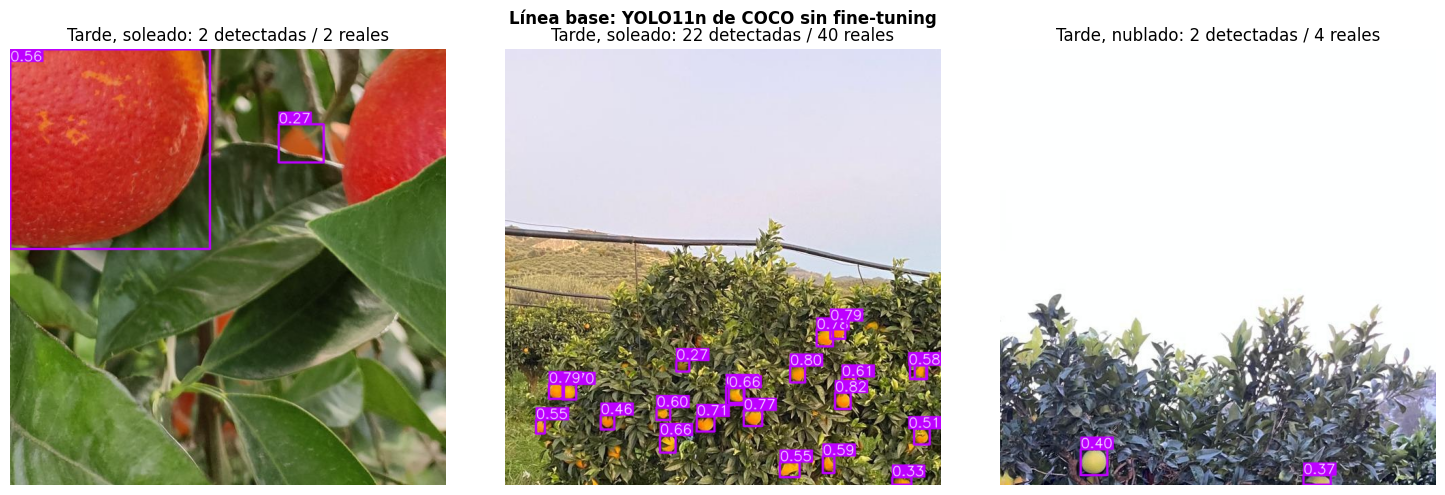

In [ ]:
# 3.5 Línea base: YOLO11n preentrenado en COCO, sin entrenar con nuestras imágenes
modelo_coco = YOLO('yolo11n.pt')
ID_NARANJA_COCO = next(k for k, v in modelo_coco.names.items() if v == 'orange')
print(f'COCO conoce {len(modelo_coco.names)} clases; "orange" es la clase {ID_NARANJA_COCO}.')

test_tabla = seleccion[seleccion['split'] == 'test']
ejemplos = test_tabla.sample(3, random_state=1)['archivo']
fig, ejes = plt.subplots(1, 3, figsize=(15, 5))
for ax, archivo in zip(ejes, ejemplos):
    r = modelo_coco.predict(str(ruta_imagen(archivo, 'test')), classes=[ID_NARANJA_COCO], conf=0.25, verbose=False)[0]
    ax.imshow(a_rgb(r.plot(labels=False)))
    ax.set_title(f'{ENTORNOS[archivo[:2]]}: {len(r.boxes)} detectadas / {len(leer_cajas(archivo, "test"))} reales')
    ax.axis('off')
plt.suptitle('Línea base: YOLO11n de COCO sin fine-tuning', fontweight='bold')
plt.tight_layout()
plt.show()

**¿Qué observar?** Compara las naranjas detectadas con las reales. Las fotos de COCO son de naranjas "de mesa", grandes y bien iluminadas;
en el campo hay naranjas pequeñas, tapadas por hojas, verdes o fotografiadas de noche. Esa diferencia entre los datos de origen
y los de destino (*domain shift*) es lo que corrige el **fine-tuning**.

### 3.6 Detección de objetos: conceptos clave
Un detector devuelve, para cada objeto: una **caja** (*bounding box*, $x_1, y_1, x_2, y_2$), una **clase** (aquí solo *orange*) y una **confianza** entre 0 y 1.

**IoU (*Intersection over Union*)** mide cuánto se parecen dos cajas:

$$\text{IoU} = \frac{\text{área de la intersección}}{\text{área de la unión}}$$

IoU = 1 es una coincidencia perfecta y IoU = 0 significa que no se tocan. Una detección se considera correcta si su IoU con una caja real es ≥ 0.5.

**NMS (*Non-Maximum Suppression*)**: los detectores suelen proponer varias cajas para el mismo objeto.
NMS se queda con la de mayor confianza y elimina las que se solapan mucho con ella (IoU alto).

### 3.7 Los tres modelos que comparamos

**YOLO (*You Only Look Once*)** es un detector de **una sola etapa**: mira la imagen una vez y, en una sola pasada por la CNN,
predice todas las cajas a la vez. Por eso es muy rápido y se usa en tiempo real. YOLO11 es una versión de 2024 de Ultralytics,
*anchor-free* (predice directamente el centro y tamaño de cada objeto) y necesita NMS al final.
Viene en varios tamaños con la misma arquitectura pero más o menos filtros y capas:

- **YOLO11n** (*nano*): el más pequeño y rápido. Pensado para dispositivos modestos.
- **YOLO11m** (*medium*): unas 8 veces más parámetros; más preciso, más lento.

**Transformers y atención.** Los Transformers (2017) nacieron para traducir texto. Su pieza clave es la **atención**:
cada elemento (una palabra, o una zona de la imagen) mira a **todos** los demás y decide cuánto le importa cada uno.

$$\text{Atención}(Q, K, V) = \text{softmax}\left(\frac{QK^\top}{\sqrt{d}}\right)V$$

$Q$ (*queries*, lo que busco), $K$ (*keys*, lo que ofrece cada elemento) y $V$ (*values*, su contenido) se calculan a partir de los datos.
Una CNN solo mira vecindarios pequeños; la atención relaciona zonas lejanas de la imagen (**contexto global**).

**RT-DETR (*Real-Time DEtection TRansformer*)** combina ambas ideas:
1. Un **backbone CNN** (HGNetv2) extrae características.
2. Un **encoder híbrido** con atención mezcla la información de toda la imagen.
3. Un **decoder** con 300 **object queries**: cada query es un "buscador" que termina prediciendo un objeto (o "nada").
4. En el entrenamiento cada objeto real se empareja con **una sola** query (emparejamiento húngaro), así que **no necesita NMS**.

| | YOLO11n | YOLO11m | RT-DETR-l |
|---|---|---|---|
| Tipo | CNN, una etapa | CNN, una etapa | CNN + Transformer |
| Parámetros (aprox.) | 2.6 M | 20 M | 32 M |
| GFLOPs (aprox., 640 px) | 6.5 | 68 | 110 |
| Necesita NMS | Sí | Sí | No |
| Punto fuerte | Velocidad | Equilibrio | Contexto global |
| Punto débil | Menos preciso con objetos difíciles | Más lento | Converge más lento, necesita más memoria y datos |

*GFLOPs = miles de millones de operaciones para procesar una imagen. Los valores reales se miden en la sección 5.*

---
## 4. Entrenamiento

### 4.1 Cómo aprende una red
1. La red hace una predicción con sus pesos actuales.
2. La **función de pérdida** (*loss*) mide cuánto se equivoca. En detección hay varias partes:
   - **pérdida de caja** (`box_loss` / `giou_loss`): qué tan lejos están las cajas predichas de las reales;
   - **pérdida de clase** (`cls_loss`): si se equivoca con la clase o la confianza;
   - YOLO añade `dfl_loss` (precisión fina de los bordes) y RT-DETR `l1_loss` (diferencia en coordenadas).
3. **Retropropagación** (*backpropagation*): se calcula el **gradiente**, es decir, en qué dirección cambiar cada peso para que la pérdida baje.
4. **Descenso de gradiente**: se da un pequeño paso en esa dirección: $w \leftarrow w - \eta \, \dfrac{\partial L}{\partial w}$, donde $\eta$ es el *learning rate*.

Vocabulario:
- **Batch**: cuántas imágenes se procesan antes de actualizar los pesos (aquí 16). Más grande = gradiente más estable pero más memoria.
- **Iteración**: una actualización de pesos. Con 700 imágenes de train y batch 16 hay 44 iteraciones por época.
- **Época**: una pasada completa por todas las imágenes de entrenamiento.

### 4.2 *Learning rate* (tasa de aprendizaje)
Es el tamaño del paso $\eta$. Es el hiperparámetro más importante:
- **Demasiado alto**: los pesos saltan de un lado a otro, la pérdida oscila o explota (`NaN`) y se puede destruir lo aprendido en COCO.
- **Demasiado bajo**: aprende muy despacio y se queda corto en las épocas disponibles.

Para elegirlo, el notebook anterior hizo un **barrido**: 15 épocas de Fase 1 con tres valores y se eligió el de mejor mAP50-95 **en validación**.
Esos resultados ya se usan en `MODELOS` (celda 1.2), así que no hace falta repetirlo:

| Modelo | lr = 1e-3 | lr = 3e-4 | lr = 1e-4 | Elegido |
|---|---|---|---|---|
| YOLO11n | **0.412** | 0.398 | 0.378 | 1e-3 |
| YOLO11m | 0.443 | **0.448** | 0.444 | 3e-4 |
| RT-DETR | **0.226** | 0.185 | 0.147 | 1e-3 |

Además, el *learning rate* **no es constante**:
- ***Warmup***: las primeras 3 épocas empieza muy bajo y sube poco a poco, para no "romper" la red al principio.
- **Decaimiento**: después baja linealmente hasta el 1 % del valor inicial, para hacer ajustes cada vez más finos.

### 4.3 Optimizador AdamW
El optimizador decide cómo dar cada paso. **AdamW** mejora el descenso de gradiente básico:
- usa **momento** (recuerda la dirección de los pasos anteriores, como una bola que rueda);
- adapta el paso **para cada peso** según lo grande que suelan ser sus gradientes;
- aplica ***weight decay***: empuja los pesos hacia valores pequeños, lo que ayuda a no sobreajustar.

### 4.4 Sobreajuste y *early stopping*
**Sobreajuste** (*overfitting*): el modelo memoriza las imágenes de entrenamiento en lugar de aprender a reconocer naranjas.
Se ve cuando la pérdida de **train sigue bajando** pero el mAP de **validación deja de subir** o empieza a bajar.

***Early stopping***: después de cada época se evalúa en validación. Si el mAP50-95 no mejora en `PACIENCIA` épocas seguidas, el entrenamiento se detiene.
Ultralytics guarda dos archivos: `last.pt` (la última época, para continuar si se corta) y **`best.pt`** (la época con mejor validación, la que usamos).

### 4.5 Aumento de datos (*data augmentation*)
En cada época las imágenes de train se modifican al azar, para que el modelo vea más variedad sin descargar más fotos:

| Ajuste | Qué hace | Por qué ayuda con naranjas |
|---|---|---|
| `hsv_h`, `hsv_s`, `hsv_v` | Cambia tono, saturación y brillo | Sol, nubes, noche |
| `translate`, `scale` | Mueve y escala la imagen | Naranjas cerca y lejos |
| `fliplr` | Espejo horizontal (50 %) | Un árbol al revés sigue siendo un árbol |
| `mosaic` | Junta 4 imágenes en una | Más objetos y contextos por imagen |

En las últimas 10 épocas de la Fase 2 se apaga el mosaico (`close_mosaic`), para terminar con imágenes realistas.
Validación y test **nunca** se aumentan.

### 4.6 *Transfer learning* y fine-tuning en dos fases
***Transfer learning***: reutilizar lo que un modelo aprendió en una tarea (COCO) para otra (naranjas de campo).
***Fine-tuning***: seguir entrenando ese modelo con nuestros datos para ajustarlo.

| | Fase 1 | Fase 2 |
|---|---|---|
| Backbone | **Congelado** (sus pesos no cambian) | Descongelado |
| Qué se entrena | Neck y head | Toda la red |
| *Learning rate* | `lr0` | `lr0 / 10` |
| Épocas máx. | 10 | 40 |

¿Por qué así? Al principio la head nueva da predicciones malas y produce gradientes grandes. Si el backbone estuviera libre,
esos gradientes podrían **borrar** los filtros útiles de COCO. Con el backbone congelado, la head aprende primero a usar esas características (además, es más rápido y usa menos memoria).
En la Fase 2 se descongela todo con un paso 10 veces más pequeño, para **ajustar con suavidad** también los filtros a las naranjas de campo.

### 4.7 Semillas y perfiles
La **semilla** fija el azar (orden de las imágenes, aumentos). Con otra semilla el mismo modelo da resultados algo distintos.
- `rapido`: 1 semilla. Suficiente para comparar y para la demo.
- `completo`: 3 semillas. Permite dar **media ± desviación**, y saber si la diferencia entre dos modelos es mayor que el "ruido" del azar.

La semilla 0 es la misma en ambos perfiles: si después pasas a `completo`, solo se entrenan las semillas 1 y 2.

### 4.8 Precisión mixta (AMP)
Normalmente cada número usa 32 bits. Con **AMP** (*Automatic Mixed Precision*) muchas operaciones se hacen con 16 bits:
casi el doble de rápido y la mitad de memoria, con prácticamente la misma precisión.

In [ ]:
# 4.9 Función de entrenamiento: salta lo terminado y continúa lo interrumpido
def entrenar(nombre_run, tipo, pesos, **ajustes):
    carpeta = RUNS / nombre_run
    if (carpeta / 'terminado.txt').exists():
        print(f'✔ Ya entrenado: {nombre_run}')
        return carpeta

    ultimo = carpeta / 'weights' / 'last.pt'
    if ultimo.exists():
        print(f'↻ Continuando: {nombre_run}')
        try:
            cargar_modelo(ultimo, tipo).train(resume=True)
        except AssertionError as e:   # Terminó justo antes de marcarse como terminado
            if 'nothing to resume' not in str(e):
                raise
    else:
        print(f'▶ Entrenando: {nombre_run}')
        shutil.rmtree(carpeta, ignore_errors=True)
        cargar_modelo(pesos, tipo).train(
            data=DATA, project=str(RUNS), name=nombre_run, exist_ok=True,
            imgsz=IMGSZ, batch=BATCH, optimizer=OPTIMIZADOR, amp=True, device=DEVICE, workers=2,
            plots=False, verbose=False, **AUMENTACION, **ajustes)

    (carpeta / 'terminado.txt').write_text('ok')
    liberar_memoria()
    return carpeta

In [ ]:
# 4.10 Entrenar los tres modelos: Fase 1 (backbone congelado) y Fase 2 (toda la red)
inicio = time.time()
for tipo, cfg in MODELOS.items():
    for semilla in SEMILLAS:
        fase1 = entrenar(f'f1_{tipo}_s{semilla}', tipo, cfg['pesos'],
                         epochs=EPOCAS_FASE1, patience=PACIENCIA, lr0=cfg['lr0'], freeze=cfg['congelar'],
                         warmup_epochs=3, close_mosaic=0, seed=semilla)
        entrenar(f'f2_{tipo}_s{semilla}', tipo, fase1 / 'weights' / 'best.pt',
                 epochs=EPOCAS_FASE2, patience=PACIENCIA, lr0=cfg['lr0'] / 10, freeze=0,
                 warmup_epochs=0, close_mosaic=10, seed=semilla)
print(f'Entrenamiento completo. Tiempo de esta ejecución: {(time.time() - inicio) / 60:.0f} min')

▶ Entrenando: f1_YOLO11n_s0
New https://pypi.org/project/ultralytics/8.4.213 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.175 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=0, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/datos_naranjas/N1000/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=11, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mo

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:1072: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:186.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


       1/10      7.28G      2.112     0.9216     0.7959         86        640: 100% ━━━━━━━━━━━━ 44/44 1.2it/s 35.6s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 1.1it/s 3.5s
                   all         98       1122    0.00231     0.0606   0.000939   0.000151

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
       2/10      6.95G      2.007     0.4125     0.7527        127        640: 0% ──────────── 0/44  0.7s

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:1072: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:186.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


       2/10      6.98G      1.772     0.3819     0.6078        185        640: 100% ━━━━━━━━━━━━ 44/44 1.3it/s 33.8s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 2.0it/s 2.0s
                   all         98       1122     0.0113      0.297     0.0362    0.00579

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
       3/10      6.73G       1.31     0.5126     0.2588        183        640: 0% ──────────── 0/44  0.8s

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:1072: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:186.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


... (57 outputs left out)

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:1072: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:186.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      22/40      11.9G     0.5828      0.692     0.1207        132        640: 100% ━━━━━━━━━━━━ 44/44 1.0s/it 44.4s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 1.9it/s 2.2s
                   all         98       1122      0.333      0.516       0.38      0.207

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size


/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:1072: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:186.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      23/40      12.5G     0.5975     0.6719     0.1252        135        640: 100% ━━━━━━━━━━━━ 44/44 1.0s/it 45.3s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 1.9it/s 2.1s
                   all         98       1122      0.367      0.552      0.413       0.22
EarlyStopping: Training stopped early as no improvement observed in last 10 epochs. Best results observed at epoch 13, best model saved as best.pt.
To update EarlyStopping(patience=10) pass a new patience value, i.e. `patience=300` or use `patience=0` to disable EarlyStopping.

23 epochs completed in 0.319 hours.
Optimizer stripped from /content/drive/MyDrive/Facultad/9no semestre/IA/Proyecto/resultados/N1000/runs/f2_RT-DETR_s0/weights/last.pt, 66.2MB
Optimizer stripped from /content/drive/MyDrive/Facultad/9no semestre/IA/Proyecto/resultados/N1000/runs/f2_RT-DETR_s0/weights/best.pt, 66.2MB

Validating /content/drive/MyDrive/Facultad/9no semestre/IA/Proyecto/res

### 4.11 Curvas de entrenamiento
La gráfica izquierda muestra el **mAP50-95 de validación** en cada época (la línea punteada vertical marca el paso de Fase 1 a Fase 2).
La derecha muestra la **pérdida total** de train (línea continua) y de validación (discontinua) de cada modelo.

Cómo leerlas:
- Si el mAP sube al empezar la Fase 2, descongelar el backbone sirvió.
- Si la pérdida de train sigue bajando pero la de validación sube, hay **sobreajuste**; *early stopping* lo corta.
- Si el mAP todavía subía en la última época, más épocas podrían mejorar el resultado.

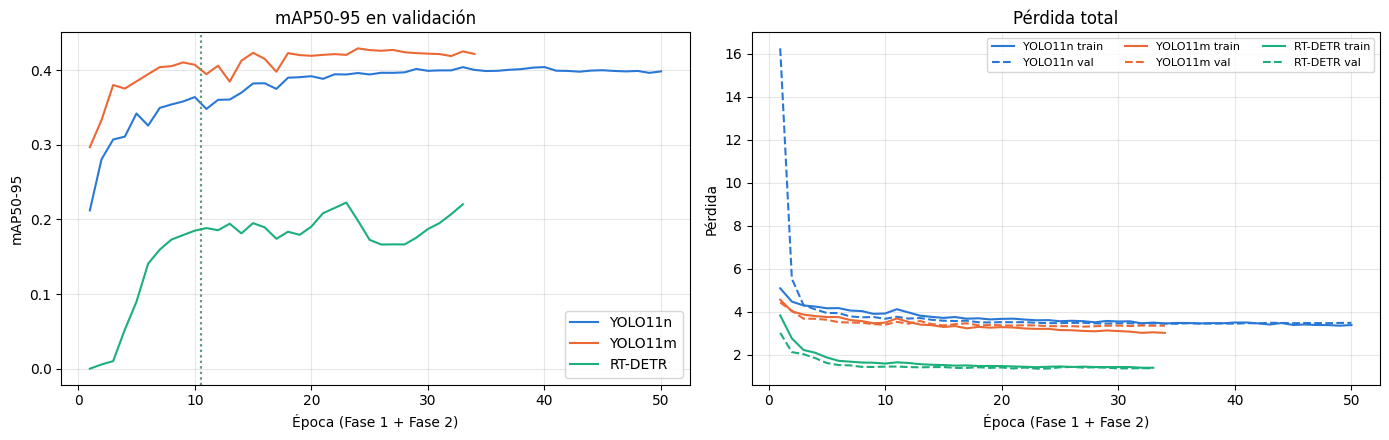

In [ ]:
# 4.12 Dibujar las curvas (semilla 0)
def leer_resultados(nombre_run):
    df = pd.read_csv(RUNS / nombre_run / 'results.csv')
    df.columns = df.columns.str.strip()
    return df


fig, (ax_map, ax_loss) = plt.subplots(1, 2, figsize=(14, 4.5))
for tipo in MODELOS:
    f1, f2 = leer_resultados(f'f1_{tipo}_s0'), leer_resultados(f'f2_{tipo}_s0')
    hist = pd.concat([f1, f2], ignore_index=True)
    epocas = np.arange(1, len(hist) + 1)
    ax_map.plot(epocas, hist['metrics/mAP50-95(B)'], color=COLORES[tipo], label=tipo)
    ax_map.axvline(len(f1) + 0.5, color=COLORES[tipo], linestyle=':', alpha=0.6)
    ax_loss.plot(epocas, hist.filter(like='train/').sum(axis=1), color=COLORES[tipo], label=f'{tipo} train')
    ax_loss.plot(epocas, hist.filter(like='val/').sum(axis=1), color=COLORES[tipo], linestyle='--', label=f'{tipo} val')
ax_map.set(title='mAP50-95 en validación', xlabel='Época (Fase 1 + Fase 2)', ylabel='mAP50-95')
ax_loss.set(title='Pérdida total', xlabel='Época (Fase 1 + Fase 2)', ylabel='Pérdida')
ax_map.legend()
ax_loss.legend(fontsize=8, ncol=3)
for ax in (ax_map, ax_loss):
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(CARPETA_RESULTADOS / 'curvas_entrenamiento.png', dpi=200, bbox_inches='tight')
plt.show()

---
## 5. Evaluación

### 5.1 Aciertos y errores en detección
Con un umbral de IoU (por ejemplo 0.5), cada detección se clasifica así:
- **TP** (verdadero positivo): la detección coincide con una naranja real que aún no estaba emparejada.
- **FP** (falso positivo): detecta una naranja donde no la hay, o repite una ya detectada.
- **FN** (falso negativo): una naranja real que nadie detectó.

No existen los "verdaderos negativos": habría infinitas cajas vacías correctamente ignoradas. Por eso la *accuracy* clásica no se usa en detección.

### 5.2 Métricas
$$\text{Precisión} = \frac{TP}{TP + FP} \qquad \text{Recall} = \frac{TP}{TP + FN} \qquad F_1 = \frac{2 \cdot \text{Precisión} \cdot \text{Recall}}{\text{Precisión} + \text{Recall}}$$

- **Precisión**: de lo que el modelo dice que es naranja, ¿cuánto lo es? (pocas falsas alarmas)
- **Recall**: de las naranjas que hay, ¿cuántas encuentra? (pocas naranjas perdidas)
- **F1**: equilibrio entre ambas (media armónica).

Todas dependen del **umbral de confianza**: con un umbral alto el modelo solo dice "naranja" cuando está muy seguro (más precisión, menos recall); con uno bajo, al revés.

**AP (*Average Precision*)**: se recorre el umbral de confianza de mayor a menor y se dibuja la **curva precisión–recall**. El AP es el área bajo esa curva,
así que resume el modelo **para todos los umbrales a la vez**. Con una sola clase, **mAP** (media de AP entre clases) es simplemente el AP de *orange*.
- **mAP50**: AP con IoU ≥ 0.5. ¿Encuentra las naranjas, aunque la caja no sea exacta?
- **mAP50-95**: media del AP con IoU = 0.50, 0.55, …, 0.95. Premia además que las cajas estén **bien ajustadas**. Es la métrica principal de COCO.

Ultralytics informa la precisión y el recall en el umbral que maximiza F1. El umbral que usaremos para la demo se elige con **validación**.

### 5.3 Reglas de la comparación
- El modelo de cada semilla es su `best.pt` de la Fase 2.
- Todas las decisiones (mejor semilla, umbral, modelo final) se toman con **validación**. Test solo se usa para informar.

In [ ]:
# 5.4 Evaluar en validación y test
def evaluar(pesos, tipo, split='test', data=None):
    """Métricas de Ultralytics para un modelo en un split. data permite evaluar en otro .yaml (p. ej. un solo entorno)."""
    modelo = cargar_modelo(pesos, tipo)
    m = modelo.val(data=data or DATA, split=split, imgsz=IMGSZ, batch=BATCH, device=DEVICE, plots=False, verbose=False,
                   project=str(CARPETA_RESULTADOS / 'validaciones'), name=f'{tipo}_{split}', exist_ok=True)
    p, r = float(m.box.mp), float(m.box.mr)
    curva_f1 = np.asarray(m.box.f1_curve)
    umbral = float(m.box.px[curva_f1.mean(axis=0).argmax()]) if curva_f1.size else 0.25
    del modelo
    liberar_memoria()
    return {'Precisión': p, 'Recall': r, 'F1': 2 * p * r / max(p + r, 1e-9),
            'mAP50': float(m.box.map50), 'mAP50-95': float(m.box.map), 'umbral': umbral}


filas = []
for tipo in MODELOS:
    for semilla in SEMILLAS:
        pesos = RUNS / f'f2_{tipo}_s{semilla}' / 'weights' / 'best.pt'
        val, test = evaluar(pesos, tipo, 'val'), evaluar(pesos, tipo, 'test')
        f1, f2 = leer_resultados(f'f1_{tipo}_s{semilla}'), leer_resultados(f'f2_{tipo}_s{semilla}')
        filas.append({'Modelo': tipo, 'Semilla': semilla,
                      **{k: v for k, v in test.items() if k != 'umbral'},
                      'mAP50-95 val': val['mAP50-95'], 'Umbral conf. (val)': val['umbral'],
                      'Épocas F1 + F2': len(f1) + len(f2),
                      'Tiempo (min)': (f1['time'].iloc[-1] + f2['time'].iloc[-1]) / 60})
por_semilla = pd.DataFrame(filas)
por_semilla.to_csv(CARPETA_RESULTADOS / 'resultados_por_semilla.csv', index=False)

# Mejor semilla de cada modelo: la de mayor mAP50-95 en validación
MEJOR = por_semilla.loc[por_semilla.groupby('Modelo')['mAP50-95 val'].idxmax()].set_index('Modelo').loc[list(MODELOS)]
PESOS_MEJORES = {tipo: RUNS / f"f2_{tipo}_s{int(MEJOR.loc[tipo, 'Semilla'])}" / 'weights' / 'best.pt' for tipo in MODELOS}

METRICAS = ['Precisión', 'Recall', 'F1', 'mAP50', 'mAP50-95']


def media_std(serie):
    return f'{serie.mean():.3f}' if serie.count() < 2 else f'{serie.mean():.3f} ± {serie.std():.3f}'


resumen = por_semilla.groupby('Modelo', sort=False)[METRICAS + ['Épocas F1 + F2', 'Tiempo (min)']].agg(media_std)
resumen.to_csv(CARPETA_RESULTADOS / 'resumen_test.csv')
print(f'Métricas en TEST ({len(SEMILLAS)} semilla(s); con varias: media ± desviación)')
display(resumen)

Ultralytics 8.4.175 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2025.9±768.5 MB/s, size: 121.7 KB)
val: Scanning /content/datos_naranjas/N1000/labels/val.cache... 98 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 98/98 34.3Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 4.1it/s 1.7s
                   all         98       1122      0.797       0.69      0.774      0.403
Speed: 1.8ms preprocess, 5.9ms inference, 0.0ms loss, 2.8ms postprocess per image
Ultralytics 8.4.175 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 40.4±22.3 MB/s, size: 130.0 KB). Use local storage instead of remote/mounted 

,Precisión,Recall,F1,mAP50,mAP50-95,Épocas F1 + F2,Tiempo (min)
Modelo,,,,,,,
YOLO11n,0.839,0.690,0.757,0.785,0.418,50.000,10.731
YOLO11m,0.857,0.717,0.781,0.810,0.438,34.000,13.127
RT-DETR,0.413,0.538,0.467,0.440,0.240,33.000,25.902


### 5.5 Resultados por entorno
El rendimiento puede cambiar mucho entre el día soleado, la noche o el interior. Aquí se evalúa el mejor modelo de cada tipo con las imágenes de test de un solo entorno.
Con pocas imágenes el resultado es poco fiable (una sola imagen difícil lo cambia mucho), por eso se marca la columna **Fiable** (≥ 30 imágenes).

In [ ]:
# 5.6 mAP50 por entorno en test
filas = []
for entorno, grupo in test_tabla.groupby('entorno'):
    lista = CARPETA_DATASET / f'test_{entorno}.txt'
    lista.write_text('\n'.join(ruta_imagen(a, 'test').as_posix() for a in grupo['archivo']), encoding='utf-8')
    yaml_entorno = CARPETA_DATASET / f'data_{entorno}.yaml'
    yaml_entorno.write_text(f'path: {CARPETA_DATASET.as_posix()}\ntrain: images/train\nval: images/val\n'
                            f'test: {lista.as_posix()}\nnames:\n  0: orange\n', encoding='utf-8')
    for tipo, pesos in PESOS_MEJORES.items():
        r = evaluar(pesos, tipo, 'test', data=str(yaml_entorno))
        filas.append({'Entorno': f'{entorno} ({ENTORNOS[entorno]})', 'Imágenes': len(grupo), 'Fiable': len(grupo) >= 30,
                      'Modelo': tipo, 'mAP50': r['mAP50']})
por_entorno = pd.DataFrame(filas).pivot_table(index=['Entorno', 'Imágenes', 'Fiable'], columns='Modelo', values='mAP50')[list(MODELOS)]
por_entorno.to_csv(CARPETA_RESULTADOS / 'map50_por_entorno.csv')
display(por_entorno.round(3))

Ultralytics 8.4.175 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1525.1±324.8 MB/s, size: 186.3 KB)
val: Scanning /content/datos_naranjas/N1000/labels/test... 38 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 38/38 1.5Kit/s 0.0s
val: New cache created: /content/datos_naranjas/N1000/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 3.7it/s 0.8s
                   all         38        868      0.861      0.711       0.81      0.399
Speed: 1.7ms preprocess, 5.9ms inference, 0.0ms loss, 1.7ms postprocess per image
Ultralytics 8.4.175 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11m summary (fused): 125 layers, 20,030,803 parameters, 0 gradients, 67.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1984.8±198.5 MB/s, size: 16

,,Modelo,YOLO11n,YOLO11m,RT-DETR
Entorno,Imágenes,Fiable,,,
"AC (Tarde, nublado)",38,True,0.810,0.825,0.412
"AS (Tarde, soleado)",22,False,0.790,0.828,0.381
"EC (Atardecer, nublado)",1,False,0.495,0.566,0.495
"ES (Atardecer, soleado)",8,False,0.824,0.842,0.417
IN (Interior),27,False,0.723,0.662,0.257
"MC (Mañana, nublado)",4,False,0.800,0.873,0.431
"MS (Mañana, soleado)",97,True,0.757,0.797,0.538
NI (Noche),3,False,0.865,0.875,0.530


### 5.7 Tamaño y velocidad
- **Parámetros**: número de pesos del modelo. Más parámetros = más capacidad, pero más memoria.
- **GFLOPs**: operaciones necesarias para procesar una imagen. Indica el coste de cálculo.
- **Latencia**: milisegundos que tarda en procesar una imagen (incluye preparar la imagen y, en YOLO, el NMS). Se toma la **mediana**, que no se ve afectada por tiempos raros.
- **FPS** (*frames per second*) = 1000 / latencia. Para tiempo real se suele pedir ≥ 25–30 FPS.

Antes de medir se hacen unas inferencias de **calentamiento**: las primeras siempre son lentas porque se reserva memoria y se preparan los cálculos.

In [ ]:
# 5.8 Medir tamaño y latencia (GPU y CPU)
def latencia_ms(modelo, imagenes, dispositivo, n):
    for imagen in imagenes[:5]:   # Calentamiento
        modelo.predict(imagen, imgsz=IMGSZ, device=dispositivo, verbose=False)
    tiempos = []
    for imagen in imagenes[:n]:
        if dispositivo != 'cpu':
            torch.cuda.synchronize()
        t0 = time.perf_counter()
        modelo.predict(imagen, imgsz=IMGSZ, device=dispositivo, verbose=False)
        if dispositivo != 'cpu':
            torch.cuda.synchronize()
        tiempos.append((time.perf_counter() - t0) * 1000)
    return float(np.median(tiempos))


imagenes_test = [cv2.imread(str(ruta_imagen(a, 'test'))) for a in test_tabla['archivo'][:60]]
filas = []
for tipo, pesos in PESOS_MEJORES.items():
    red = cargar_modelo(pesos, tipo).model
    fila = {'Modelo': tipo, 'Parámetros (M)': get_num_params(red) / 1e6, 'GFLOPs': get_flops(red, IMGSZ),
            'Archivo (MB)': pesos.stat().st_size / 1e6}
    if torch.cuda.is_available():   # Un modelo recién cargado por dispositivo
        fila['GPU (ms/img)'] = latencia_ms(cargar_modelo(pesos, tipo), imagenes_test, DEVICE, 60)
        fila['GPU (FPS)'] = 1000 / fila['GPU (ms/img)']
    fila['CPU (ms/img)'] = latencia_ms(cargar_modelo(pesos, tipo), imagenes_test, 'cpu', 20)
    fila['CPU (FPS)'] = 1000 / fila['CPU (ms/img)']
    filas.append(fila)
    liberar_memoria()
velocidad = pd.DataFrame(filas).set_index('Modelo')
velocidad['GPU usada'] = GPU
velocidad.to_csv(CARPETA_RESULTADOS / 'tamano_y_velocidad.csv')
display(velocidad.round(1))

,Parámetros (M),GFLOPs,Archivo (MB),GPU (ms/img),GPU (FPS),CPU (ms/img),CPU (FPS),GPU usada
Modelo,,,,,,,,
YOLO11n,2.6,6.6,5.5,11.0,91.2,151.8,6.6,Tesla T4
YOLO11m,20.1,68.3,40.5,24.5,40.9,834.4,1.2,Tesla T4
RT-DETR,32.8,109.9,66.2,41.1,24.3,1193.0,0.8,Tesla T4


---
## 6. Gráficas de la comparación

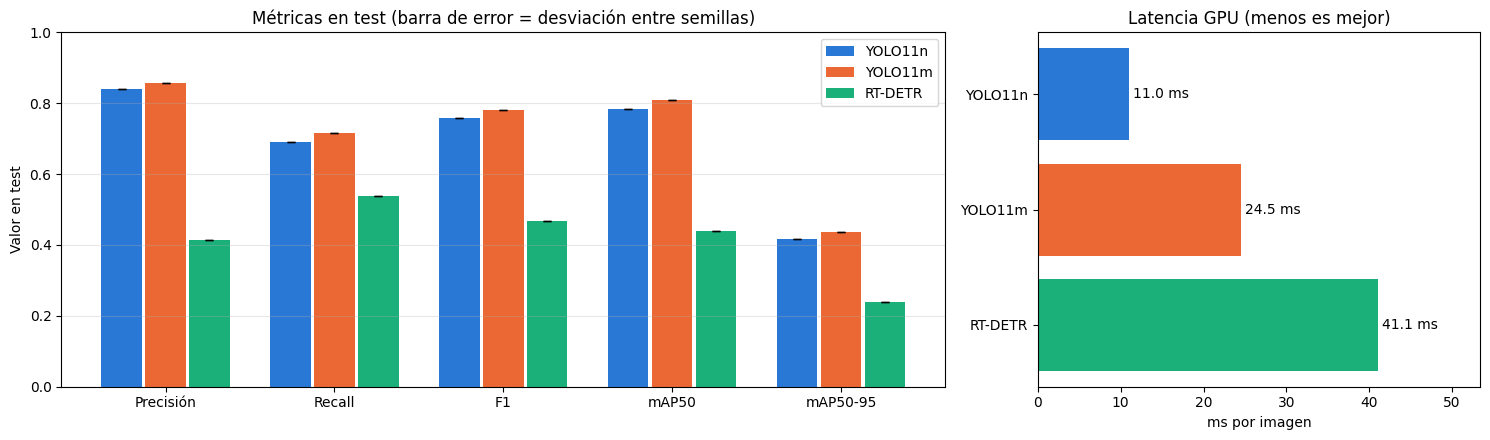

In [ ]:
# 6.1 Métricas en test y velocidad
fig, (ax_met, ax_vel) = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={'width_ratios': [2, 1]})
x = np.arange(len(METRICAS))
ancho = 0.26
for i, tipo in enumerate(MODELOS):
    g = por_semilla[por_semilla['Modelo'] == tipo][METRICAS]
    ax_met.bar(x + (i - 1) * ancho, g.mean(), ancho * 0.92, yerr=g.std().fillna(0), capsize=3,
               color=COLORES[tipo], label=tipo)
ax_met.set_xticks(x, METRICAS)
ax_met.set(ylim=(0, 1), ylabel='Valor en test', title='Métricas en test (barra de error = desviación entre semillas)')
ax_met.legend()
ax_met.grid(axis='y', alpha=0.3)

columna = 'GPU (ms/img)' if 'GPU (ms/img)' in velocidad else 'CPU (ms/img)'
barras = ax_vel.barh(list(MODELOS), velocidad[columna], color=[COLORES[t] for t in MODELOS])
ax_vel.bar_label(barras, labels=[f'{v:.1f} ms' for v in velocidad[columna]], padding=3)
ax_vel.invert_yaxis()
ax_vel.set(title=f'Latencia {columna.split()[0]} (menos es mejor)', xlabel='ms por imagen',
           xlim=(0, velocidad[columna].max() * 1.3))
plt.tight_layout()
plt.savefig(CARPETA_RESULTADOS / 'comparacion.png', dpi=200, bbox_inches='tight')
plt.show()

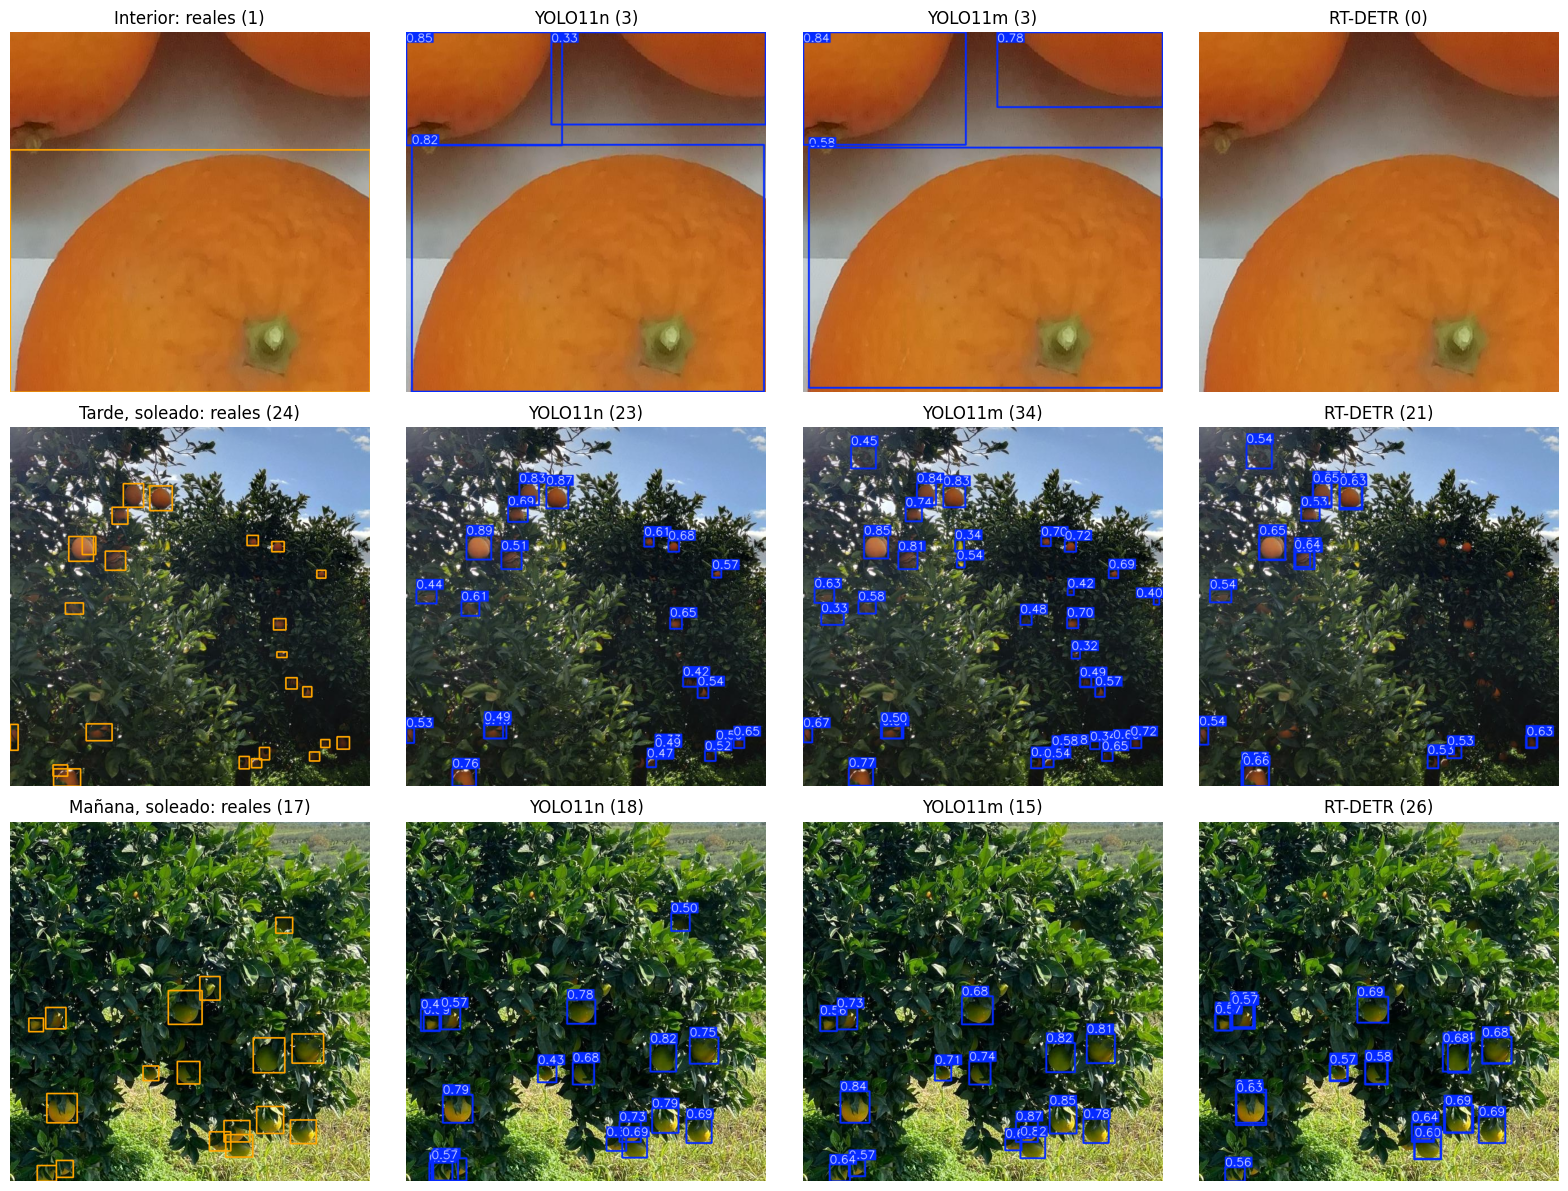

In [ ]:
# 6.2 Comparación visual sobre las mismas imágenes de test (una de interior si hay)
modelos_finales = {tipo: cargar_modelo(pesos, tipo) for tipo, pesos in PESOS_MEJORES.items()}
interior = test_tabla[test_tabla['entorno'] == 'IN']['archivo'].sample(frac=1, random_state=0).head(1)
otras = test_tabla[test_tabla['entorno'] != 'IN']['archivo'].sample(frac=1, random_state=0).head(3 - len(interior))
muestra = list(interior) + list(otras)

fig, ejes = plt.subplots(len(muestra), len(MODELOS) + 1, figsize=(4 * (len(MODELOS) + 1), 4 * len(muestra)), squeeze=False)
for fila, archivo in enumerate(muestra):
    imagen = cv2.imread(str(ruta_imagen(archivo, 'test')))
    reales = imagen.copy()
    cajas = leer_cajas(archivo, 'test', imagen.shape[1], imagen.shape[0])
    for x1, y1, x2, y2 in cajas.astype(int):
        cv2.rectangle(reales, (x1, y1), (x2, y2), (0, 165, 255), 2)
    ejes[fila, 0].imshow(a_rgb(reales))
    ejes[fila, 0].set_title(f'{ENTORNOS[archivo[:2]]}: reales ({len(cajas)})')
    for col, (tipo, modelo) in enumerate(modelos_finales.items(), start=1):
        r = modelo.predict(imagen, conf=float(MEJOR.loc[tipo, 'Umbral conf. (val)']), imgsz=IMGSZ, verbose=False)[0]
        ejes[fila, col].imshow(a_rgb(r.plot(labels=False)))
        ejes[fila, col].set_title(f'{tipo} ({len(r.boxes)})')
for ax in ejes.flat:
    ax.axis('off')
plt.tight_layout()
plt.savefig(CARPETA_RESULTADOS / 'comparacion_visual.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 7. Guardar los modelos y elegir el modelo final
Se copian los mejores pesos de cada modelo a la carpeta `modelos/` del proyecto, con nombres claros, y se escribe `modelos.json` con:
qué modelo es el final, el umbral de confianza de cada uno y sus métricas.

El **modelo final** es el de mayor **mAP50-95 en validación**. No se elige con test: si eligiéramos "el que mejor sale en test",
el número de test dejaría de ser una medida honesta de cómo funcionará con imágenes nuevas.
Si para tu caso importa más la velocidad (por ejemplo, una cámara en tiempo real sin GPU), mira también la tabla de la sección 5.8.

In [ ]:
# 7.1 Guardar
FINAL = MEJOR['mAP50-95 val'].idxmax()
info = {'final': FINAL, 'experimento': NOMBRE_EXPERIMENTO, 'perfil': PERFIL, 'imgsz': IMGSZ, 'modelos': {}}
for tipo, pesos in PESOS_MEJORES.items():
    archivo = f"orange_{tipo.lower().replace('-', '')}.pt"
    shutil.copy(pesos, CARPETA_MODELOS / archivo)
    info['modelos'][tipo] = {'archivo': archivo,
                             'umbral_conf': round(float(MEJOR.loc[tipo, 'Umbral conf. (val)']), 3),
                             'mAP50-95 val': round(float(MEJOR.loc[tipo, 'mAP50-95 val']), 4),
                             'mAP50-95 test': round(float(MEJOR.loc[tipo, 'mAP50-95']), 4)}
(CARPETA_MODELOS / 'modelos.json').write_text(json.dumps(info, indent=2, ensure_ascii=False), encoding='utf-8')
print(json.dumps(info, indent=2, ensure_ascii=False))
print(f'\nModelo final: {FINAL}. Archivos en {CARPETA_MODELOS}')

{
  "final": "YOLO11m",
  "experimento": "N1000",
  "perfil": "rapido",
  "imgsz": 640,
  "modelos": {
    "YOLO11n": {
      "archivo": "orange_yolo11n.pt",
      "umbral_conf": 0.317,
      "mAP50-95 val": 0.4034,
      "mAP50-95 test": 0.4176
    },
    "YOLO11m": {
      "archivo": "orange_yolo11m.pt",
      "umbral_conf": 0.263,
      "mAP50-95 val": 0.4296,
      "mAP50-95 test": 0.4376
    },
    "RT-DETR": {
      "archivo": "orange_rtdetr.pt",
      "umbral_conf": 0.527,
      "mAP50-95 val": 0.2231,
      "mAP50-95 test": 0.2397
    }
  }
}

Modelo final: YOLO11m. Archivos en /content/drive/MyDrive/Facultad/9no semestre/IA/Proyecto/modelos


---
## 8. Usar el modelo entrenado (sin volver a entrenar)
Los modelos quedan guardados en `modelos/` dentro de la carpeta del proyecto. Para usarlos otro día **no hace falta entrenar de nuevo**:
1. Ejecuta las celdas de la **sección 1** (instalación, configuración, carpetas y funciones).
2. Ejecuta las celdas de esta sección.

También puedes usar los modelos fuera de este notebook con dos líneas:
```python
from ultralytics import YOLO        # para RT-DETR: from ultralytics import RTDETR
modelo = YOLO('modelos/orange_yolo11m.pt')
modelo.predict('foto.jpg', conf=0.3, show=True)
```

In [ ]:
# 8.1 Cargar los modelos guardados
info_modelos = json.loads((CARPETA_MODELOS / 'modelos.json').read_text(encoding='utf-8'))
MODELO_FINAL = info_modelos['final']
modelos_listos = {tipo: cargar_modelo(CARPETA_MODELOS / d['archivo'], tipo) for tipo, d in info_modelos['modelos'].items()}
UMBRALES = {tipo: d['umbral_conf'] for tipo, d in info_modelos['modelos'].items()}
print('Modelos cargados:', list(modelos_listos), '| final:', MODELO_FINAL)


def mostrar_detecciones(imagen, comparar=True):
    """Dibuja las naranjas detectadas. imagen = ruta o imagen de OpenCV. comparar=True usa los tres modelos."""
    if not isinstance(imagen, np.ndarray):
        ruta = imagen
        imagen = cv2.imread(str(ruta))
        if imagen is None:
            print(f'No se pudo leer {ruta}. Usa una imagen .jpg o .png.')
            return
    tipos = list(modelos_listos) if comparar else [MODELO_FINAL]
    fig, ejes = plt.subplots(1, len(tipos), figsize=(6 * len(tipos), 6), squeeze=False)
    for ax, tipo in zip(ejes[0], tipos):
        r = modelos_listos[tipo].predict(imagen, conf=UMBRALES[tipo], imgsz=IMGSZ, verbose=False)[0]
        ax.imshow(a_rgb(r.plot(labels=False)))
        ax.set_title(f'{tipo}: {len(r.boxes)} naranjas (conf ≥ {UMBRALES[tipo]:.2f})')
        ax.axis('off')
    plt.tight_layout()
    plt.show()

Modelos cargados: ['YOLO11n', 'YOLO11m', 'RT-DETR'] | final: YOLO11m


### 8.2 Probar con una imagen subida (sin cámara)
- **En Colab**: al ejecutar la celda aparece un botón *Elegir archivos*; puedes subir una o varias fotos.
- **En tu computadora**: escribe la ruta de tus fotos en `IMAGENES_LOCALES`.

Pon `COMPARAR_LOS_TRES = False` para ver solo el modelo final.

Saving OrangeBloss_wb.jpg to OrangeBloss_wb.jpg


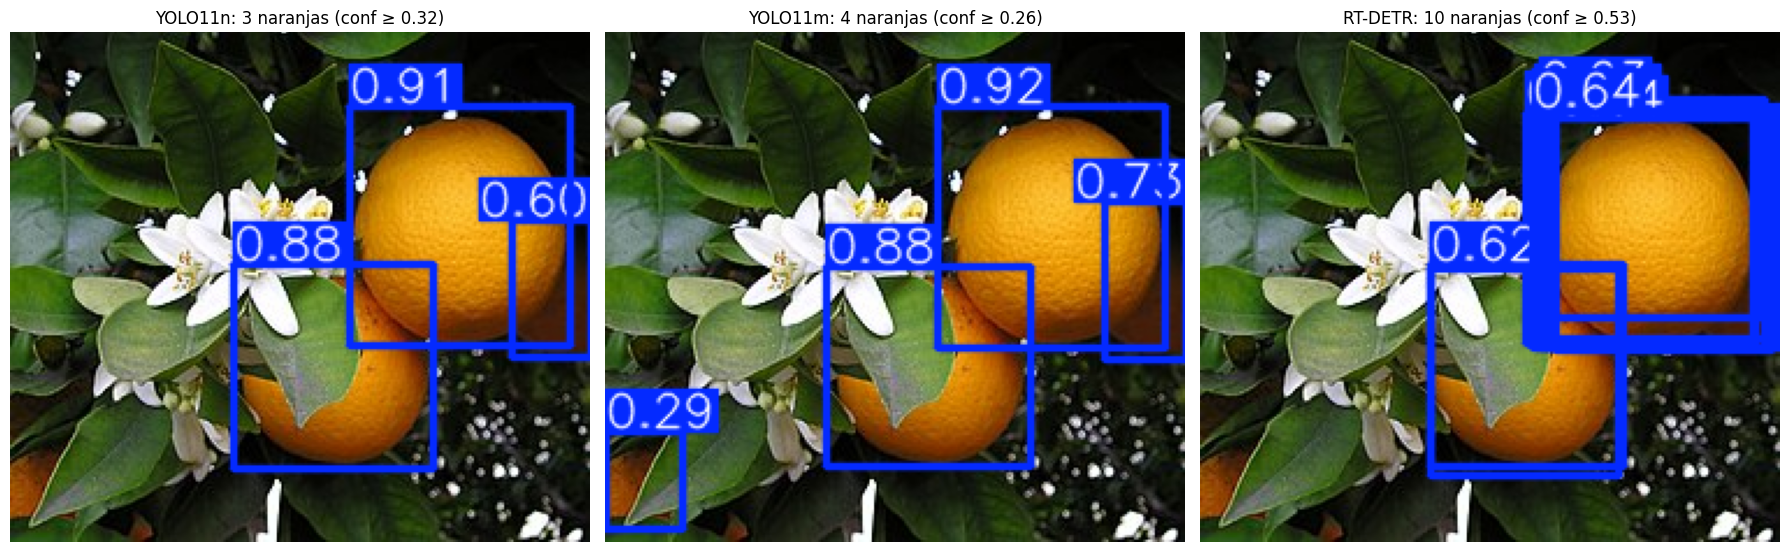

In [ ]:
# 8.2 Subir imágenes y detectar naranjas
COMPARAR_LOS_TRES = True
IMAGENES_LOCALES = ['naranjas.jpg']   # Solo se usa fuera de Colab

if EN_COLAB:
    from google.colab import files
    rutas = list(files.upload())     # Guarda las fotos subidas en /content
else:
    rutas = [r for r in IMAGENES_LOCALES if Path(r).exists()]
    if not rutas:
        print('No se encontró ninguna imagen en IMAGENES_LOCALES; se usa una de test como ejemplo.')
        rutas = [ruta_imagen(test_tabla['archivo'].iloc[0], 'test')] if 'test_tabla' in globals() else []

for ruta in rutas:
    mostrar_detecciones(ruta, comparar=COMPARAR_LOS_TRES)

### 8.3 Webcam en tiempo real (solo en tu computadora)
Colab se ejecuta en un servidor remoto y no puede abrir una ventana de video. En tu computadora (Jupyter o VS Code), pon `USAR_WEBCAM = True`.
Se abre una ventana con las naranjas detectadas, el conteo y los FPS. Pulsa **q** o **ESC** para salir.

In [ ]:
# 8.3 Detección en vivo con la webcam
USAR_WEBCAM = False
CAMARA = 0   # Si tienes varias cámaras, prueba 1 o 2


def detectar_en_webcam(tipo=None, camara=0):
    tipo = tipo or MODELO_FINAL
    modelo, umbral = modelos_listos[tipo], UMBRALES[tipo]
    cap = cv2.VideoCapture(camara)
    if not cap.isOpened():
        print(f'No se pudo abrir la cámara {camara}.')
        return
    anterior = time.time()
    try:
        while True:
            ok, frame = cap.read()
            if not ok:
                break
            r = modelo.predict(frame, conf=umbral, imgsz=IMGSZ, verbose=False)[0]
            frame = r.plot(labels=False)
            ahora = time.time()
            fps, anterior = 1 / max(ahora - anterior, 1e-6), ahora
            cv2.rectangle(frame, (0, 0), (330, 70), (0, 0, 0), -1)
            cv2.putText(frame, f'{tipo}  FPS: {fps:.1f}', (10, 28), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 0), 2)
            cv2.putText(frame, f'Naranjas: {len(r.boxes)}', (10, 58), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 165, 255), 2)
            cv2.imshow('Orange Vision', frame)
            if cv2.waitKey(1) & 0xFF in (ord('q'), 27):
                break
    finally:
        cap.release()
        cv2.destroyAllWindows()


if USAR_WEBCAM and not EN_COLAB:
    detectar_en_webcam(camara=CAMARA)
elif USAR_WEBCAM:
    print('En Colab usa la celda 8.4 para tomar una foto con la cámara del navegador.')

### 8.4 Foto con la cámara del navegador (Colab)
En Colab sí se puede tomar **una foto** con la cámara de tu navegador. Pon `TOMAR_FOTO = True`, ejecuta la celda y pulsa el botón que aparece.

In [ ]:
# 8.4 Tomar una foto en Colab y detectar naranjas
TOMAR_FOTO = False

if TOMAR_FOTO and EN_COLAB:
    import base64
    from IPython.display import Javascript, display
    from google.colab.output import eval_js

    display(Javascript("""
    async function tomarFoto(calidad) {
      const div = document.createElement('div');
      const boton = document.createElement('button');
      boton.textContent = 'Tomar foto';
      const video = document.createElement('video');
      video.style.display = 'block';
      const stream = await navigator.mediaDevices.getUserMedia({video: true});
      document.body.appendChild(div);
      div.appendChild(boton);
      div.appendChild(video);
      video.srcObject = stream;
      await video.play();
      await new Promise((resolve) => boton.onclick = resolve);
      const canvas = document.createElement('canvas');
      canvas.width = video.videoWidth;
      canvas.height = video.videoHeight;
      canvas.getContext('2d').drawImage(video, 0, 0);
      stream.getVideoTracks()[0].stop();
      div.remove();
      return canvas.toDataURL('image/jpeg', calidad);
    }
    """))
    datos = eval_js('tomarFoto(0.9)')
    Path('foto_webcam.jpg').write_bytes(base64.b64decode(datos.split(',')[1]))
    mostrar_detecciones('foto_webcam.jpg', comparar=True)
elif TOMAR_FOTO:
    print('Esta celda es para Colab. En tu computadora usa la celda 8.3.')

---
## 9. Glosario rápido

| Término | Significado breve |
|---|---|
| Neurona / peso | Unidad que multiplica entradas por pesos, suma y aplica una activación. Los pesos son lo que se aprende |
| CNN | Red que usa filtros que se deslizan por la imagen (convolución) para extraer características |
| Feature map | Resultado de aplicar un filtro: un "mapa" de dónde aparece cierta característica |
| Backbone / neck / head | Extraer características / combinar escalas / predecir cajas y clases |
| Transformer / atención | Arquitectura donde cada parte de la entrada pondera a todas las demás (contexto global) |
| YOLO | Detector de una etapa: predice todas las cajas en una sola pasada |
| RT-DETR | Detector en tiempo real basado en Transformers; no necesita NMS |
| Preentrenado / COCO | Modelo ya entrenado en un dataset grande (COCO: 118k imágenes, 80 clases) |
| Transfer learning | Reutilizar lo aprendido en una tarea para otra |
| Fine-tuning | Seguir entrenando un modelo preentrenado con datos propios |
| Congelar capas | Impedir que ciertos pesos cambien durante el entrenamiento |
| Función de pérdida | Número que mide cuánto se equivoca el modelo; el entrenamiento lo minimiza |
| Gradiente / retropropagación | Dirección en que cambiar cada peso / algoritmo que la calcula |
| Learning rate | Tamaño del paso al actualizar los pesos |
| Warmup | Empezar con un learning rate pequeño e ir subiéndolo |
| Optimizador (AdamW) | Regla para actualizar los pesos a partir del gradiente |
| Batch / iteración / época | Imágenes por actualización / una actualización / una pasada por todo train |
| Sobreajuste | Memorizar train en lugar de generalizar |
| Early stopping / paciencia | Parar cuando validación deja de mejorar / cuántas épocas esperar |
| Aumento de datos | Modificaciones aleatorias de las imágenes de train |
| Semilla | Número que fija el azar para poder repetir un experimento |
| AMP | Usar números de 16 bits para entrenar más rápido |
| Train / val / test | Aprender / decidir / medir el resultado final |
| Fuga de datos | Que información del test se cuele en el entrenamiento |
| IoU | Solapamiento entre dos cajas (intersección / unión) |
| NMS | Eliminar cajas duplicadas del mismo objeto |
| TP / FP / FN | Acierto / falsa alarma / objeto no detectado |
| Precisión / recall / F1 | Calidad de las detecciones / cobertura de objetos / equilibrio |
| mAP50 / mAP50-95 | Área bajo la curva precisión-recall con IoU 0.5 / promediada entre IoU 0.5 y 0.95 |
| Umbral de confianza | Confianza mínima para aceptar una detección |
| Parámetros / GFLOPs | Tamaño del modelo / coste de cálculo por imagen |
| Latencia / FPS | Tiempo por imagen / imágenes por segundo |